# Q1

In [ ]:
# Creating the df with only the categories and the percentage changing. 
df_pct_cat_monthly = df_project_categories.pct_change()

df_pct_cat_monthly = df_pct_cat_monthly.loc[:, 
    (df_pct_cat_monthly.columns != "Consumer_Price_Index") &
     (df_pct_cat_monthly.columns != "Average_Hourly_Wage")]
# Dropping the first row (Null row, no previous data)

df_pct_cat_monthly = df_pct_cat_monthly.dropna(how="all")

# Creating pivot table per year.

df_pct_pivot = df_pct_cat_monthly.pivot_table(
    index = df_pct_cat_monthly.index.year,
    aggfunc="mean")

# Creating interactive plots for each category.

import plotly.graph_objects as go
from plotly.subplots import make_subplots

categories = df_pct_pivot.columns

fig = make_subplots(
    rows=3,
    cols=4,
    subplot_titles=categories,
    horizontal_spacing=0.04,
    vertical_spacing=0.10
)

for i, column in enumerate(categories):
    row = (i // 4) + 1
    col = (i % 4) + 1

    fig.add_trace(
        go.Scatter(
            x=df_pct_pivot.index,
            y=df_pct_pivot[column],
            mode="lines+markers",
            name=column,
            hovertemplate=(
                f"Category: {column}<br>"
                "Year: %{x}<br>"
                "Change: %{y:.2%}"
                "<extra></extra>"
            )
        ),
        row=row,
        col=col
    )

    fig.add_vrect(
        x0=2019,
        x1=2022,
        fillcolor="gray",
        opacity=0.25,
        line_width=0,
        row=row,
        col=col
    )

fig.update_layout(
    title="Percentage Change by Grocery Category, 2015–2025",
    width=1400,
    height=900,
    template="plotly_white",
    showlegend=False
)

fig.update_xaxes(dtick=1)
fig.update_yaxes(tickformat=".1%")

fig.show()

## These plots I created using AI because they are interactive. 

# Answering the question. 

# Gathering values from 2015 to 2025

df_price_changes = df_project_categories.loc[((df_project_categories.index.year == 2015) | (df_project_categories.index.year == 2025)), :]

df_price_changes = df_price_changes.loc[:, 
    (df_price_changes.columns != "Consumer_Price_Index") &
    (df_price_changes.columns != "Average_Hourly_Wage")]

# Creating one df for each year

price_2015 = df_price_changes[df_price_changes.index.year == 2015].copy()
price_2025 = df_price_changes[df_price_changes.index.year == 2025].copy()

price_2015.index = price_2015.index.month
price_2025.index = price_2025.index.month

# Gathering the change between months of both years. 

monthly_difference = (price_2025 - price_2015)
monthly_change_pct = monthly_difference / price_2015
monthly_change_pct

# Plotting

fig = go.Figure()

for column in monthly_change_pct.columns:
    fig.add_trace(
        go.Scatter(
            x=monthly_change_pct.index,
            y=monthly_change_pct[column],
            mode="lines",
            name=column,
            line_shape="spline",
            hovertemplate=(
                "Category: %{fullData.name}<br>"
                "Month: %{x}<br>"
                "Change: %{y:.2%}"
                "<extra></extra>"
            )
        )
    )

fig.update_layout(
    title="Monthly Grocery Category Price Changes",
    width=1200,
    height=700,
    xaxis_title="Month",
    yaxis_title="Percentage Change: 2015 to 2025",
    xaxis=dict(dtick=1),
    yaxis=dict(tickformat=".1%"),
    hovermode="closest",
    template="plotly_white",
    legend=dict(
        orientation="h",
        y=-0.2,
        x=0
    ),
    margin=dict(b=130)
)

fig.show()

### These plots I created using AI because they are interactive. 


# Ranking the mean per category. 

monthly_change_pct_mean = monthly_change_pct.mean()

monthly_change_pct_mean.sort_values(ascending=False)

# Plotting the mean final.
import plotly.express as px

categories = monthly_change_pct.columns
plotly_colors = px.colors.qualitative.Plotly

category_colors = {
    category: plotly_colors[i % len(plotly_colors)]
    for i, category in enumerate(categories)
}

ranked_categories = (
    monthly_change_pct_mean
    .sort_values(ascending=False)
    .rename("average_percentage_change")
    .reset_index()
)

ranked_categories.columns = ["category", "average_percentage_change"]

fig = px.bar(
    ranked_categories,
    x="category",
    y="average_percentage_change",
    color="category",
    color_discrete_map=category_colors,
    hover_data={
        "category": True,
        "average_percentage_change": ":.2%"
    }
)

fig.update_layout(
    title="Average Grocery Category Price Change: 2015 to 2025",
    xaxis_title="Grocery Category",
    yaxis_title="Average Percentage Change",
    template="plotly_white",
    width=1200,
    height=650,
    showlegend=False
)

fig.update_yaxes(tickformat=".1%")
fig.add_hline(y=0, line_width=1, line_color="black")

fig.show()

# Q2

In [1]:
item_to_cat = (df_groceries[["item", "category"]]
               .drop_duplicates()
               .set_index("item")["category"]
               .reindex(df_groceries__items.columns))

basket = df_groceries__items.T.groupby(item_to_cat).sum().T
n_items = item_to_cat.value_counts()

# 2. High-inflation months (same CPI flag as before) -- 
# 4% given the inflation rates have been generally steady at 2-3% historically / allows us to see impact of COVID

THRESHOLD = 4.0
cpi_yoy = df_index["Consumer_Price_Index"].pct_change(12) * 100
high_months = cpi_yoy[cpi_yoy >= THRESHOLD].index

print(cpi_yoy)

# 3. Baseline period
# justification for 2019: it is the most recent year before COVID-19 that we believe is most appropriate for baseline
# also shows the impact of COVID-19

BASE_START, BASE_END = "2019-01-01", "2019-12-01"
baseline = basket.loc[BASE_START:BASE_END].mean()

# 4. Compare against baseline: high-inflation average, peak, and latest month
high_avg = basket.loc[high_months].mean()
peak     = basket.loc[high_months].max()
latest   = basket.iloc[-1]

results = pd.DataFrame({
    "n_items": n_items,
    "baseline": baseline,
    "usd_change_high": high_avg - baseline,
    "pct_change_high": (high_avg / baseline - 1) * 100,
    "usd_change_peak": peak - baseline,
    "pct_change_peak": (peak / baseline - 1) * 100,
    "usd_change_latest": latest - baseline,
    "pct_change_latest": (latest / baseline - 1) * 100,
})

# Dollar change per item, since categories have different numbers of items
results["usd_change_high_per_item"] = results["usd_change_high"] / results["n_items"]

print(results.sort_values("pct_change_high", ascending=False).round(2))
print(results.sort_values("pct_change_peak", ascending = False))
print(peak)


# ______________________________________________________________________________

# Visualization
import matplotlib.pyplot as plt

# Chart 1: Which categories rose the most during high inflation?
order = results.sort_values("pct_change_high", ascending=True)

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(order.index, order["pct_change_high"])
for bar, val in zip(bars, order["pct_change_high"]):
    ax.text(val + 1, bar.get_y() + bar.get_height() / 2, f"{val:.0f}%", va="center")
ax.set_xlabel("Avg high-inflation period prices vs. baseline (%)")
ax.set_ylabel("Grocery categories")
ax.set_title("Average % change during high-inflation months")
plt.tight_layout()
plt.show()

# Chart 2: High-inflation average vs. peak vs. latest month
# high-inflation average -- take the months of high inflation CPI and average the costs
cmp = (results.sort_values("pct_change_high", ascending=False)
       [["pct_change_high", "pct_change_peak", "pct_change_latest"]])
cmp.columns = ["High-inflation avg", "Peak", "Latest month"]

ax = cmp.plot(kind="bar", figsize=(12, 6))
ax.set_ylabel("% change vs. baseline")
ax.set_title("High-inflation average vs. peak vs. latest")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Chart 3: Price paths over time (baseline = 100) with CPI inflation above
basket_idx = basket / basket.loc[BASE_START:BASE_END].mean() * 100

# Eggs (peak ~446) would squash the other lines, so plot it separately
outliers = ["Eggs"]
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True,
                         gridspec_kw={"height_ratios": [1, 2.5]})

axes[0].plot(cpi_yoy.index, cpi_yoy, color="black")
axes[0].axhline(THRESHOLD, linestyle="--", color="red")
axes[0].set_ylabel("CPI YoY %")
axes[0].set_title("Inflation (top) and price change over time: 2015 - 2025 (bottom)")

for col in basket_idx.columns.drop(outliers):
    axes[1].plot(basket_idx.index, basket_idx[col], label=col)
axes[1].axhline(100, color="gray", linewidth=0.8)
axes[1].set_ylabel("Price change")
axes[1].legend(ncol=2, fontsize=8)

for a in axes:
    a.axvspan(high_months.min(), high_months.max(), alpha=0.15, color="red")
plt.tight_layout()
plt.show()

NameError: name 'df_groceries' is not defined

# Q3

In [ ]:
# Step 1: first and last price of every item
first_price = df_groceries__items.iloc[0]
last_price  = df_groceries__items.iloc[-1]

print(first_price, last_price)

# Step 2: build a results table with both dollar and percent change
item_results = pd.DataFrame({"first_price": first_price, "last_price": last_price})
item_results["usd_change"] = item_results["last_price"] - item_results["first_price"]
item_results["pct_increase"] = (item_results["last_price"] / item_results["first_price"] - 1) * 100

print(item_results)

# Step 3: add category and unit so each number has context
item_info = (df_groceries[["item", "category", "unit"]]
             .drop_duplicates()
             .set_index("item"))
item_results = item_results.join(item_info)

print(item_results)

# Step 4: rank by percent increase and keep the top 10
item_results = item_results.sort_values("pct_increase", ascending=False)
top5 = item_results.head(5)
print(top5.round(2))


# Step 5: rebase the top 10 to Jan 2015 = 100 for the line chart
top5_names = top5.index
rebased = df_groceries__items[top5_names] / df_groceries__items[top5_names].iloc[0] * 100

# Step 6: draw both charts side by side
import matplotlib.pyplot as plt
fig, axes = plt.subplots(figsize=(12, 6))

top5_sorted = top5.sort_values("pct_increase")
axes.barh(top5_sorted.index, top5_sorted["pct_increase"])
for i, v in enumerate(top5_sorted["pct_increase"]):
    axes.text(v + 0.5, i, f"{v:.0f}%", va="center")
axes.set_xlabel("% price increase, Jan 2015 to Dec 2025")
axes.set_title("Top 5 items by % increase")

plt.tight_layout()
plt.show()

# Q4

In [ ]:
#calculate total % change from Jan 2015 to Dec 2025
first_month = df_project_categories.iloc[0]
last_month = df_project_categories.iloc[-1]
total_change_pct = ((last_month / first_month) - 1) * 100

#separate categories from CPI
cat_changes = total_change_pct.drop(['Consumer_Price_Index', 'Average_Hourly_Wage'])
cpi_change = total_change_pct['Consumer_Price_Index']

#sort categories for a clean plot
cat_changes = cat_changes.sort_values(ascending=False)

#plotting
plt.figure(figsize=(10, 5))
cat_changes.plot(kind='bar', color='skyblue', label='Grocery Category')
plt.axhline(y=cpi_change, color='red', linestyle='--', label=f'Overall CPI ({cpi_change:.1f}%)')

plt.title('Grocery category price increases vs. Overall inflation (2015-2025)')
plt.ylabel('Total Percent Change (%)')
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.show()

Grocery: (8869, 8)
CPI: (957, 2)
Wages: (247, 2)
category
Eggs                    204.59
Pantry and snacks        73.63
Beef                     55.14
Meat, broad category     49.58
Drinks                   35.95
Bakery and grains        33.63
Poultry                  33.61
Energy                   29.46
Dairy and fats           27.90
Vegetables               27.42
Pork and deli            27.06
Fruit                    24.37
Name: change_pct, dtype: float64
CPI growth (2019-2025): 25.08%
                      Category Growth (%)  CPI Growth (%)  Difference (pp)
category                                                                  
Eggs                               204.59           25.08           179.51
Pantry and snacks                   73.63           25.08            48.54
Beef                                55.14           25.08            30.06
Meat, broad category                49.58           25.08            24.50
Drinks                              35.95           25.0

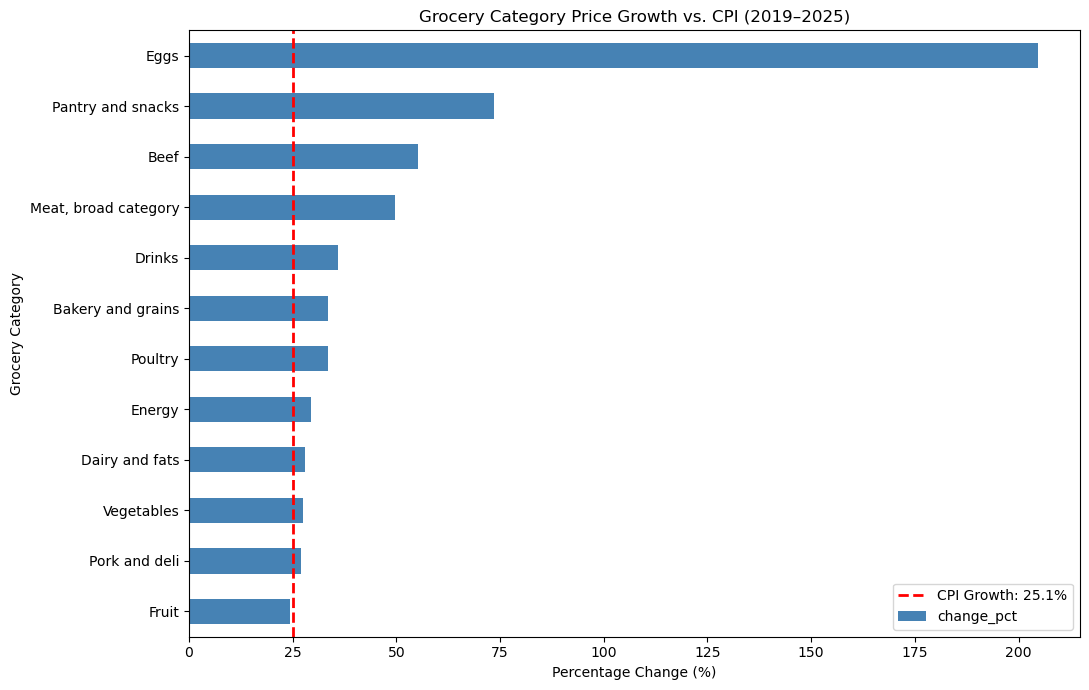

In [2]:
"""
Created on Thu Nov 14 14:36:21 2026

@author: 922995473
"""

#Import libraries and load data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

grocery = pd.read_csv("us_average_prices_monthly (1.csv")
cpi = pd.read_csv("Consumer_Price_Index.csv")
wages = pd.read_csv("Average_Hourly_Wages.csv")

grocery["date"] = pd.to_datetime(grocery["date"])
cpi["observation_date"] = pd.to_datetime(cpi["observation_date"])
wages["observation_date"] = pd.to_datetime(wages["observation_date"])

print("Grocery:", grocery.shape)
print("CPI:", cpi.shape)
print("Wages:", wages.shape)

#Calculate category price changes
# Select the two comparison years
grocery["year"] = grocery["date"].dt.year

selected = grocery[grocery["year"].isin([2019, 2025])].copy()

# Average price for each item in each year
item_prices = (
    selected.groupby(
        ["category", "series_id", "year"]
    )["price"]
    .mean()
    .unstack()
)

# Keep items with prices in both years
item_prices = item_prices.dropna(subset=[2019, 2025])

# Calculate percentage change for each item
item_prices["change_pct"] = (
    (item_prices[2025] / item_prices[2019] - 1) * 100
)

# Average item percentage changes by category
category_changes = (
    item_prices.groupby(level="category")["change_pct"]
    .mean()
    .sort_values(ascending=False)
)

print(category_changes.round(2))

#Question 4: Compare grocery inflation with CPI
# Calculate annual average CPI
cpi["year"] = cpi["observation_date"].dt.year

cpi_annual = cpi.groupby("year")["CPIULFSL"].mean()

cpi_change = (
    (cpi_annual.loc[2025] / cpi_annual.loc[2019] - 1) * 100
)

print(f"CPI growth (2019-2025): {cpi_change:.2f}%")

# Identify categories above overall inflation
q4_results = pd.DataFrame({
    "Category Growth (%)": category_changes
})

q4_results["CPI Growth (%)"] = cpi_change
q4_results["Difference (pp)"] = (
    q4_results["Category Growth (%)"] - cpi_change
)

print(q4_results.round(2))

# Visualization
ax = category_changes.sort_values().plot(
    kind="barh",
    figsize=(11, 7),
    color="steelblue"
)

ax.axvline(
    cpi_change,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"CPI Growth: {cpi_change:.1f}%"
)

plt.title("Grocery Category Price Growth vs. CPI (2019–2025)")
plt.xlabel("Percentage Change (%)")
plt.ylabel("Grocery Category")
plt.legend()
plt.tight_layout()
plt.savefig("Ari_Q4_CPI_Comparison.png", dpi=300)
plt.show()

# Q5

In [3]:
# get wage change
wage_change = total_change_pct['Average_Hourly_Wage']

print(f"Average Hourly Wage Increase (2015-2025): {wage_change:.2f}%\n")

# find categories that outpaced wages
outpaced_wages = cat_changes[cat_changes > wage_change]
print("Categories that increased FASTER than wages:")
print(outpaced_wages)

plt.figure(figsize=(10, 5))
cat_changes.plot(kind='bar', color='lightgreen', label='Grocery Category')
plt.axhline(y=wage_change, color='purple', linestyle='--', label=f'Avg Hourly Wage ({wage_change:.1f}%)')

plt.title('Grocery Category Price Increases vs. Hourly Wage Growth (2015-2025)')
plt.ylabel('Total Percent Change (%)')
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.show()

NameError: name 'total_change_pct' is not defined

In [ ]:
#Question 5: Compare grocery inflation with wages
# Calculate annual average hourly wages
wages["year"] = wages["observation_date"].dt.year

wage_annual = wages.groupby("year")["CES0500000003"].mean()

wage_change = (
    (wage_annual.loc[2025] / wage_annual.loc[2019] - 1) * 100
)

print(f"Hourly wage growth (2019-2025): {wage_change:.2f}%")

# Compare category growth with wage growth
q5_results = pd.DataFrame({
    "Category Growth (%)": category_changes
})

q5_results["Wage Growth (%)"] = wage_change
q5_results["Difference (pp)"] = (
    q5_results["Category Growth (%)"] - wage_change
)

q5_results["Faster Than Wages"] = (
    q5_results["Difference (pp)"] > 0
)

print(q5_results.round(2))

# Visualization
ax = category_changes.sort_values().plot(
    kind="barh",
    figsize=(11, 7),
    color="darkorange"
)

ax.axvline(
    wage_change,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Wage Growth: {wage_change:.1f}%"
)

plt.title("Grocery Category Price Growth vs. Hourly Wages (2019–2025)")
plt.xlabel("Percentage Change (%)")
plt.ylabel("Grocery Category")
plt.legend()
plt.tight_layout()
plt.savefig("Ari_Q5_Wage_Comparison.png", dpi=300)
plt.show()
# Question 5: Final summary

print("\nQUESTION 5: FINAL RESULTS")
print("-" * 50)

print(f"Average hourly wage growth: {wage_change:.2f}%")

# Select categories that increased faster than wages
faster_categories = q5_results[
    q5_results["Faster Than Wages"] == True
]

print("\nGrocery categories that increased faster than wages:")
print(faster_categories[["Category Growth (%)", "Difference (pp)"]].round(2))

print(
    f"\nTotal: {len(faster_categories)} out of "
    f"{len(q5_results)} categories increased faster than wages."
)

# Save results
q5_results.to_csv("Ari_Q5_Results.csv")

print("\nQuestion 5 results saved successfully!")
